# Notebook from the .py script


In [37]:
# %% load k-space data, display rsos combination across coils for all slices

from matplotlib import pyplot as plt
import scipy.io as sio
# load LIBRARY file with defined functions
import LIBRARY as lib

import numpy as np
import sigpy as sp

import sigpy.mri as mri
import sigpy.mri.app as app

import h5py

# Loading file, getting k space data, processing images : flip, cropping and performing perform 2-D inverse discrete Fourier Transform.

## Infos regarding h5 file and h (py package)
.h5 files opened as h5py._hl.files.File.
File ows 3 keys : ['ismrmrd_header', 'kspace', 'reconstruction_rss'] <br>
[ISMRM Data Format  (MRD)](https://ismrmrd.readthedocs.io/en/latest/) <br>
In the 'ismrmrd_header' are informations about the configuration of the IRM acquisition as xml file. <br>
'kspace' data and 'reconstruction_rss' are also available


In [44]:
#loading .h5 file with The h5py package (Pythonic interface to the HDF5 binary data format) as a h5py._hl.files.File
file_name = 'file_brain_AXT2_205_2050058.h5' 
hf = h5py.File(file_name)

type(hf)

/data_local/data_hdd/lehmansy/tmp/ipykernel_64290/1008275528.py:3: H5pyDeprecationWarning: The default file mode will change to 'r' (read-only) in h5py 3.0. To suppress this warning, pass the mode you need to h5py.File(), or set the global default h5.get_config().default_file_mode, or set the environment variable H5PY_DEFAULT_READONLY=1. Available modes are: 'r', 'r+', 'w', 'w-'/'x', 'a'. See the docs for details.
  hf = h5py.File(file_name)


h5py._hl.files.File

In [9]:
list(hf.keys())

['ismrmrd_header', 'kspace', 'reconstruction_rss']

In [24]:
header = hf['ismrmrd_header'][()]
header

b'<?xml version="1.0" encoding="utf-8"?>\n<ismrmrdHeader xmlns="http://www.ismrm.org/ISMRMRD" xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.ismrm.org/ISMRMRD ismrmrd.xsd">\n   <studyInformation>\n      <studyTime>17:12:13</studyTime>\n   </studyInformation>\n   <measurementInformation>\n      <measurementID>141513_2549038_2549046_561</measurementID>\n      <patientPosition>HFS</patientPosition>\n      <protocolName>AX</protocolName>\n      <frameOfReferenceUID>1.3.12.2.1107.5.2.18.141513.1.20180208164929957.0.0.5009</frameOfReferenceUID>\n   </measurementInformation>\n   <acquisitionSystemInformation>\n      <systemVendor>SIEMENS</systemVendor>\n      <systemModel>Aera</systemModel>\n      <systemFieldStrength_T>1.494</systemFieldStrength_T>\n      <relativeReceiverNoiseBandwidth>0.793</relativeReceiverNoiseBandwidth>\n      <receiverChannels>20</receiverChannels>\n      <coilLabel>\n         <coilNumber

In [15]:
type(hf['ismrmrd_header'])

h5py._hl.dataset.Dataset

##  Getting kspace data, converting them in numpy array, transpose the array, perform 2-D inverse discrete Fourier Transform.
- kspace are in h5py._hl.dataset.Dataset format and are converted in numpy array <br>
"kspace": shape (16, 20, 640, 320) from ismrmrd_header : matrixSize 640 x; y 320; z1 Number of coils = 20  == receiverChannels
receiverChannels <br>
- transpose to (640, 320, 20, 16)
- then perform 2-D inverse discrete Fourier Transform.


In [18]:
hf['kspace']

<HDF5 dataset "kspace": shape (16, 20, 640, 320), type "<c8">

In [8]:
volume_kspace = hf['kspace'][()]
volume_kspace

array([[[[ 1.75740570e-06+6.81169331e-06j,
           1.25519000e-06-5.17186709e-06j,
           1.50804408e-06+3.29222530e-07j, ...,
           8.75955448e-06-4.50666994e-06j,
          -2.32155435e-06-2.65426934e-08j,
           2.01351941e-06-9.74535942e-06j],
         [-3.48174945e-06+1.07351225e-05j,
          -1.33318827e-06-6.89411536e-07j,
           3.45986336e-06+5.18048182e-07j, ...,
           9.63825732e-06-1.33861322e-05j,
           3.30922194e-06+6.57211058e-06j,
           8.26781616e-06+5.82938083e-06j],
         [-2.32923776e-06+6.43986277e-06j,
          -6.49155118e-06-4.31225635e-06j,
           1.31572597e-06+3.51760536e-06j, ...,
           4.86616045e-07-7.25430436e-06j,
          -5.52111305e-06+4.74252738e-06j,
          -3.01422551e-06+8.33161175e-06j],
         ...,
         [-3.00281681e-06-6.19934872e-06j,
           5.08851372e-06-6.53346069e-06j,
          -1.13970600e-06+1.77975744e-06j, ...,
           3.91528010e-06+9.08435322e-06j,
          -4.6573

In [20]:
type(volume_kspace)

numpy.ndarray

In [22]:
volume_kspace.shape

(16, 20, 640, 320)

In [26]:
# all slices:
kspace_all = np.transpose(volume_kspace, (2, 3, 1, 0))
kspace_all.shape

(640, 320, 20, 16)

In [ ]:
img_all = lib.ifft2call(kspace_all, 0, 1)
img_all.shape

(640, 320, 20, 16)

In [29]:
# flip the image upside down  
img_all = np.flipud(img_all)  

In [30]:
# Determine the size of the 0th dimension -> remove 2x readout over-sampling
dim0_size = img_all.shape[0]
dim0_size

640

In [43]:
# Calculate the start and end indices for cropping
# calls 2 functions define in LIBRARY files/
start_idx = (dim0_size - 320) // 2
end_idx = start_idx + 320

# Crop the middle 320 points in the 0th dimension
img_cropped = img_all[start_idx:end_idx, :, :, :]
img_cropped.shape



(320, 320, 20, 16)

# Handling multi-coil data
- perform rsos function that combine multi-coil images into a single image by computing the pixel-wise root-sum-of-squares across the coil dimension.
-

In [ ]:
# rsos function that combine multi-coil images into a single image by computing 
# the pixel-wise root-sum-of-squares across the coil dimension.
img_cropped_rsos = lib.rsos(img_cropped, 2)
img_cropped_rsos.shape

(320, 320, 16)

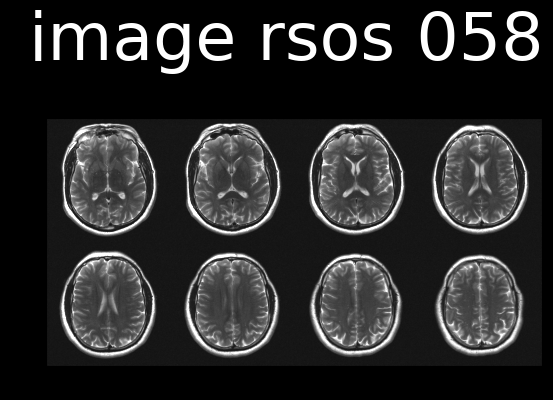

In [ ]:
# mosaic function takes arguments : (img, num_row, num_col, fig_num, clim, title = '', use_transpose = False, use_flipud = False
lib.mosaic(img_cropped_rsos[:,:,0:8], 2, 4, 1, [0,5e-4], 'image rsos 058', 0, 0)

# Save the current figure as a .png file
plt.savefig('image_rsos_058.png', dpi=300, bbox_inches='tight')


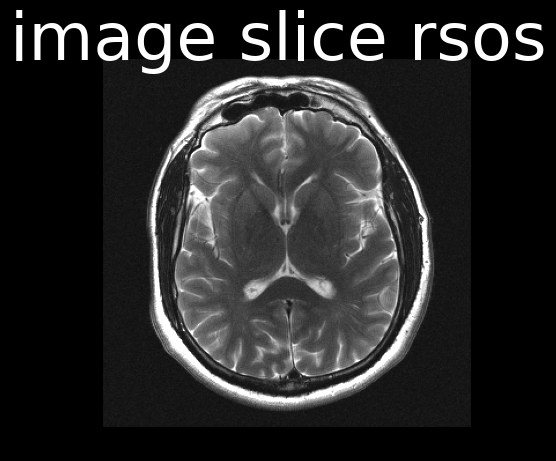

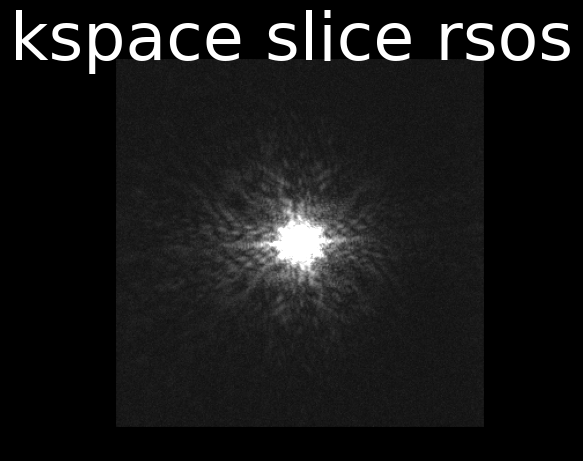

In [ ]:
# %% select a slice from the cropped image

slice_index = 1  # Select the 1st slice (0-based index)
img = img_cropped[:,:,:,slice_index]

#Combining multi coil images into 1 single image
img_rsos = lib.rsos(img, 2)

# Create kspace from image with 2-D discrete Fourier transform and then combine multi coil images into a single one
kspace = lib.fft2call(img, 0, 1)
kspace_rsos = lib.rsos(kspace, 2)

lib.mosaic(img_rsos, 1, 1, 2, [0,5e-4], 'image slice rsos', 0, 0)
lib.mosaic(kspace_rsos, 1, 1, 3, [0,5e-4], 'kspace slice rsos', 0, 0)